In [1]:
# ==========================================
# CELL 1: CHUẨN BỊ DỮ LIỆU VÀ FEATURE SCALING
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Đọc dữ liệu sạch
df = pd.read_csv('../data/processed/train_cleaned.csv')
X = df.drop(columns=['price_range'])
y = df['price_range']

# 2. Phân chia Train/Test (80/20) phân tầng
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Chuẩn hóa đặc trưng (fit trên train, transform trên cả train và test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Số lượng mẫu huấn luyện: {X_train.shape[0]}")
print(f"Số lượng mẫu kiểm thử: {X_test.shape[0]}")

Số lượng mẫu huấn luyện: 1600
Số lượng mẫu kiểm thử: 400


In [2]:
# ==========================================
# CELL 2: BENCHMARK NHIỀU THUẬT TOÁN KHÁC NHAU
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    "SVM (Linear Kernel)": SVC(kernel='linear', C=1.0, random_state=42),
    "SVM (RBF Kernel)": SVC(kernel='rbf', C=1.0, random_state=42)
}

results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, clf in models.items():
    cv_scores = cross_val_score(clf, X_train_scaled, y_train, cv=cv, scoring='accuracy')
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    test_acc = accuracy_score(y_test, y_pred)

    results.append({
        "Model": name,
        "CV Mean Accuracy (%)": round(cv_scores.mean() * 100, 2),
        "CV Std (%)": round(cv_scores.std() * 100, 2),
        "Test Accuracy (%)": round(test_acc * 100, 2)
    })

summary_df = pd.DataFrame(results).sort_values(by="Test Accuracy (%)", ascending=False)
display(summary_df)

,Model,CV Mean Accuracy (%),CV Std (%),Test Accuracy (%)
0,Logistic Regression,94.69,0.91,96.25
4,SVM (Linear Kernel),95.38,0.57,96.25
3,Random Forest,86.19,2.35,87.75
5,SVM (RBF Kernel),85.19,1.13,86.00
2,Decision Tree,84.00,0.85,85.25
1,K-Nearest Neighbors,50.37,1.32,53.00


In [3]:
# ==========================================
# CELL 3: TINH CHỈNH SIÊU THAM SỐ (HYPERPARAMETER TUNING)
# ==========================================
# Tinh chỉnh tham số C cho Linear SVM (mô hình triển vọng nhất)
param_grid = {
    'C': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]
}

grid_search = GridSearchCV(
    estimator=SVC(kernel='linear', random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print(f"Tham số tốt nhất (Best Params): {grid_search.best_params_}")
print(f"Độ chính xác CV tốt nhất: {round(grid_search.best_score_ * 100, 2)}%")

cv_results_df = pd.DataFrame(grid_search.cv_results_)
display(cv_results_df[[
    'param_C', 'mean_test_score', 'std_test_score', 'rank_test_score'
]].sort_values('param_C'))

best_model = grid_search.best_estimator_

Tham số tốt nhất (Best Params): {'C': 10.0}
Độ chính xác CV tốt nhất: 96.0%


--- CLASSIFICATION REPORT (BEST MODEL) ---
              precision    recall  f1-score   support

     Class 0       0.99      0.99      0.99       100
     Class 1       0.97      0.95      0.96       100
     Class 2       0.94      0.96      0.95       100
     Class 3       0.98      0.98      0.98       100

    accuracy                           0.97       400
   macro avg       0.97      0.97      0.97       400
weighted avg       0.97      0.97      0.97       400



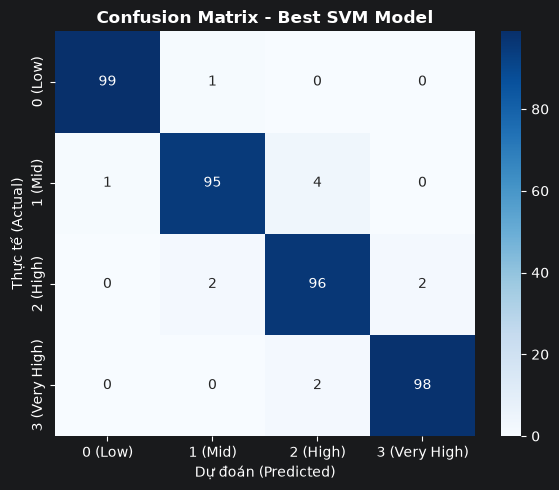

In [4]:
# ==========================================
# CELL 4: MA TRẬN NHẦM LẪN VÀ BÁO CÁO PHÂN LOẠI
# ==========================================
y_pred_best = best_model.predict(X_test_scaled)

print("--- CLASSIFICATION REPORT (BEST MODEL) ---")
print(classification_report(y_test, y_pred_best, target_names=['Class 0', 'Class 1', 'Class 2', 'Class 3']))

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['0 (Low)', '1 (Mid)', '2 (High)', '3 (Very High)'],
            yticklabels=['0 (Low)', '1 (Mid)', '2 (High)', '3 (Very High)'])
plt.title('Confusion Matrix - Best SVM Model', fontweight='bold')
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.tight_layout()
plt.savefig(
    '../reports/figures/confusion_matrix_best_model.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white',  # Ép toàn bộ khung viền về màu trắng tinh
)
plt.show()

<Figure size 1000x600 with 0 Axes>

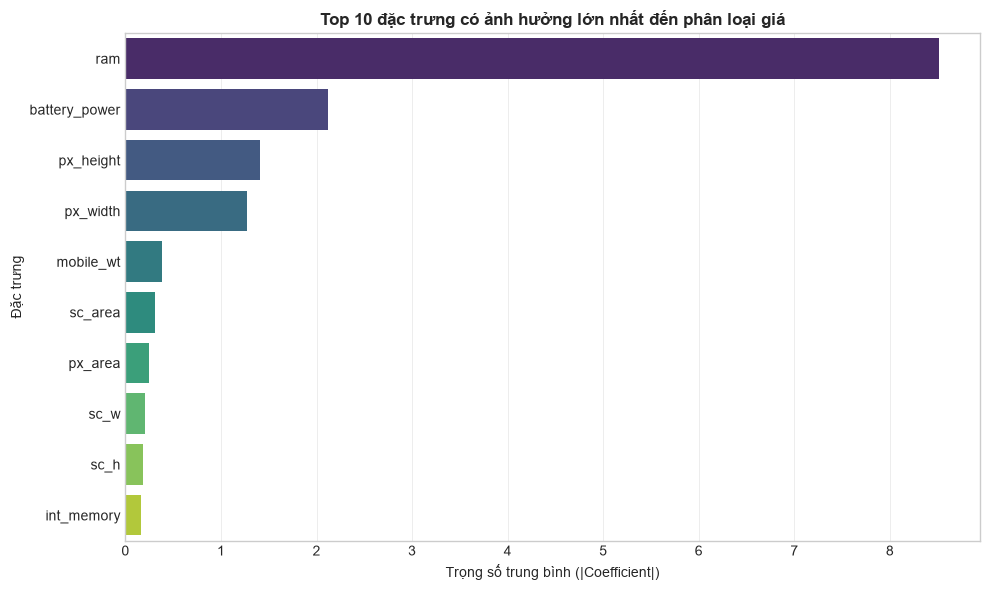

Top 10 đặc trưng quan trọng nhất:


,Feature,Importance
13,ram,8.516655
0,battery_power,2.122077
11,px_height,1.404275
12,px_width,1.267425
8,mobile_wt,0.383344
21,sc_area,0.312271
20,px_area,0.244814
15,sc_w,0.201342
14,sc_h,0.181234
6,int_memory,0.165592


In [5]:
# ==========================================
# CELL 5: PHÂN TÍCH TRỌNG SỐ ĐẶC TRƯNG (ĐÃ FIX WARNING)
# ==========================================
# Lấy trọng số tuyệt đối trung bình từ các siêu phẳng của Linear SVM
importance = np.mean(np.abs(best_model.coef_), axis=0)
feature_names = X.columns

feat_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.style.use('seaborn-v0_8-whitegrid')  # hoặc plt.style.use('default')
fig, ax = plt.subplots(figsize=(10, 6), facecolor='white')
ax.set_facecolor('white')
# Thêm hue='Feature' và legend=False để fix FutureWarning
sns.barplot(
    data=feat_importance_df.head(10),
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title('Top 10 đặc trưng có ảnh hưởng lớn nhất đến phân loại giá', fontweight='bold')
plt.xlabel('Trọng số trung bình (|Coefficient|)')
plt.ylabel('Đặc trưng')
plt.tight_layout()
plt.savefig(
    '../reports/figures/feature_importance.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white',
    edgecolor='none',
)
plt.show()

# Hiển thị bảng giá trị cụ thể
print("Top 10 đặc trưng quan trọng nhất:")
display(feat_importance_df.head(10))

In [6]:
# ==========================================
# CELL 6: LƯU TRỮ METRICS VÀ MODEL ĐỂ DEPLOY
# ==========================================
# 1. Lưu metrics vào file JSON
report_dict = classification_report(y_test, y_pred_best, output_dict=True)
with open('../reports/metrics.json', 'w') as f:
    json.dump(report_dict, f, indent=4)

# 2. Đóng gói mô hình và bộ scaler vào thư mục models/
joblib.dump(best_model, '../models/best_svm_model.joblib')
joblib.dump(scaler, '../models/scaler.joblib')

print("✓ Đã lưu metrics vào reports/metrics.json")
print("✓ Đã lưu mô hình tốt nhất vào models/best_svm_model.joblib")
print("✓ Đã lưu bộ chuẩn hóa vào models/scaler.joblib")

✓ Đã lưu metrics vào reports/metrics.json
✓ Đã lưu mô hình tốt nhất vào models/best_svm_model.joblib
✓ Đã lưu bộ chuẩn hóa vào models/scaler.joblib


In [7]:
# ==========================================
# TRÍCH XUẤT 12 TRƯỜNG HỢP DỰ ĐOÁN SAI
# ==========================================
# 1. Tạo điều kiện lọc các mẫu đoán sai (Thực tế != Dự đoán)
misclassified_mask = y_test != y_pred_best

# 2. Lấy dữ liệu phần cứng gốc từ X_test kèm nhãn Thực tế và Dự đoán
df_errors = X_test[misclassified_mask].copy()
df_errors['Thực tế (Actual)'] = y_test[misclassified_mask]
df_errors['Dự đoán (Predicted)'] = y_pred_best[misclassified_mask]

# Đổi nhãn số sang tên phân khúc cho dễ đọc
class_names = {0: '0 (Low)', 1: '1 (Mid)', 2: '2 (High)', 3: '3 (Very High)'}
df_errors['Thực tế'] = df_errors['Thực tế (Actual)'].map(class_names)
df_errors['Dự đoán'] = df_errors['Dự đoán (Predicted)'].map(class_names)

print(f"Tổng số mẫu dự đoán sai: {len(df_errors)} mẫu\n")

# 3. Hiển thị các đặc trưng quan trọng nhất (RAM, Pin, Màn hình) để phân tích nguyên nhân
important_cols = [
    'ram',
    'battery_power',
    'px_height',
    'px_width',
    'mobile_wt',
    'Thực tế',
    'Dự đoán',
]
display(df_errors[important_cols])

Tổng số mẫu dự đoán sai: 12 mẫu



,ram,battery_power,px_height,px_width,mobile_wt,Thực tế,Dự đoán
387,2360,560,356.0,1903,146,1 (Mid),2 (High)
1341,2253,1423,501.0,640,131,1 (Mid),2 (High)
733,2799,720,1347.0,1733,96,3 (Very High),2 (High)
751,1026,1331,1109.0,1226,165,1 (Mid),0 (Low)
1968,635,1667,1211.0,1396,138,0 (Low),1 (Mid)
55,2552,1936,667.0,1036,104,2 (High),3 (Very High)
924,1252,1966,1242.0,1973,144,2 (High),1 (Mid)
1176,2836,1590,1058.0,1109,187,3 (Very High),2 (High)
1164,2832,860,1573.0,1581,170,2 (High),3 (Very High)
403,1529,1476,1641.0,1666,171,2 (High),1 (Mid)


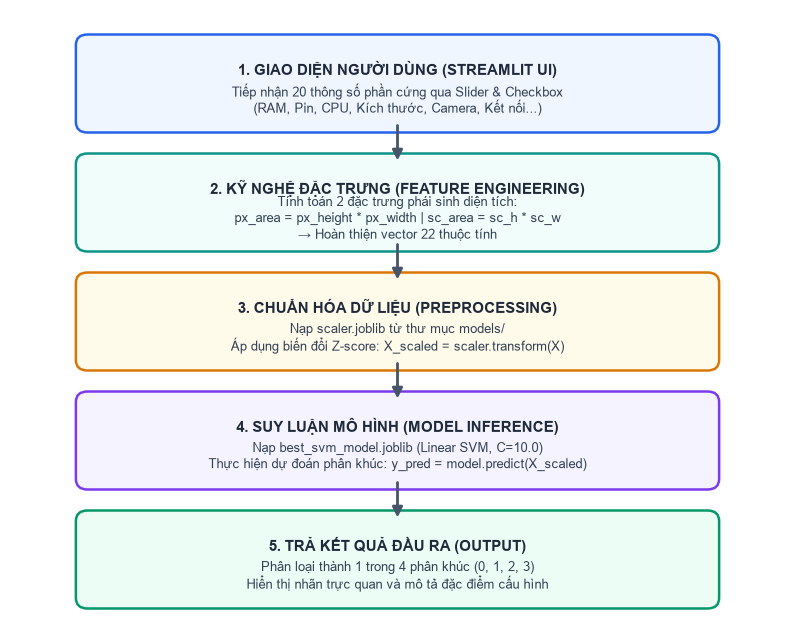

✓ Đã xuất ảnh thành công tại: ../reports/figures/system_pipeline_flow.png


In [8]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8), facecolor="white")
ax.set_facecolor("white")

# Danh sách các khối trong luồng (Tên khối, Nội dung chi tiết, Màu viền, Màu nền)
steps = [
    (
        "1. GIAO DIỆN NGƯỜI DÙNG (STREAMLIT UI)",
        "Tiếp nhận 20 thông số phần cứng qua Slider & Checkbox\n(RAM, Pin, CPU, Kích thước, Camera, Kết nối...)",
        "#2563EB",
        "#EFF6FF",
    ),
    (
        "2. KỸ NGHỆ ĐẶC TRƯNG (FEATURE ENGINEERING)",
        "Tính toán 2 đặc trưng phái sinh diện tích:\npx_area = px_height * px_width | sc_area = sc_h * sc_w\n→ Hoàn thiện vector 22 thuộc tính",
        "#0D9488",
        "#F0FDFA",
    ),
    (
        "3. CHUẨN HÓA DỮ LIỆU (PREPROCESSING)",
        "Nạp scaler.joblib từ thư mục models/\nÁp dụng biến đổi Z-score: X_scaled = scaler.transform(X)",
        "#D97706",
        "#FFFBEB",
    ),
    (
        "4. SUY LUẬN MÔ HÌNH (MODEL INFERENCE)",
        "Nạp best_svm_model.joblib (Linear SVM, C=10.0)\nThực hiện dự đoán phân khúc: y_pred = model.predict(X_scaled)",
        "#7C3AED",
        "#F5F3FF",
    ),
    (
        "5. TRẢ KẾT QUẢ ĐẦU RA (OUTPUT)",
        "Phân loại thành 1 trong 4 phân khúc (0, 1, 2, 3)\nHiển thị nhãn trực quan và mô tả đặc điểm cấu hình",
        "#059669",
        "#ECFDF5",
    ),
]

y_positions = [6.8, 5.1, 3.4, 1.7, 0.0]
box_width, box_height = 8.0, 1.1

for i, (title, desc, border_col, fill_col) in enumerate(steps):
  y = y_positions[i]
  # Vẽ khối hình chữ nhật bo góc
  rect = patches.FancyBboxPatch(
      (-box_width / 2, y),
      box_width,
      box_height,
      boxstyle="round,pad=0.15",
      linewidth=1.8,
      edgecolor=border_col,
      facecolor=fill_col,
  )
  ax.add_patch(rect)

  # Tiêu đề khối
  ax.text(
      0,
      y + 0.75,
      title,
      fontsize=11,
      fontweight="bold",
      color="#1E293B",
      ha="center",
      va="center",
  )
  # Mô tả nội dung bên trong
  ax.text(
      0,
      y + 0.32,
      desc,
      fontsize=9.5,
      color="#334155",
      ha="center",
      va="center",
      linespacing=1.3,
  )

  # Vẽ mũi tên liên kết giữa các khối
  if i < len(steps) - 1:
    ax.annotate(
        "",
        xy=(0, y_positions[i + 1] + box_height + 0.05),
        xytext=(0, y - 0.05),
        arrowprops=dict(
            arrowstyle="-|>",
            color="#475569",
            lw=2.0,
            mutation_scale=15,
            shrinkA=0,
            shrinkB=0,
        ),
    )

# Cân chỉnh không gian trục
ax.set_xlim(-5, 5)
ax.set_ylim(-0.4, 8.4)
ax.axis("off")

# Lưu trực tiếp vào thư mục reports/figures/
plt.savefig(
    "../reports/figures/system_pipeline_flow.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="none",
)
plt.show()
print("✓ Đã xuất ảnh thành công tại: ../reports/figures/system_pipeline_flow.png")